# D · Multi-layer perceptron for DK1 day-ahead prices

**Question.** Does a small feed-forward network that predicts all 24 delivery hours at once beat the
project lead's frozen Ridge baseline on the same hours — and is any gain consistent enough across
months to justify the extra training time?

**Protocol.** Every number below uses the team's shared snapshot (`team/data/`), the shared hourly
scoring (`team_benchmark_core.metric`) and the shared benchmark (`scripts/run_team_benchmark.py`):
monthly refits on expanding history, inputs and targets standardised inside the training window only,
one row per Copenhagen delivery day and 24 prices in EUR/MWh. Settings are chosen on the **2023
months only**; 2024 is never used for a choice and is reported as the later development year. Both
years are historical development data, so everything here is exploratory.

**Folder.** `model.py` (the chosen network), `tuning.py` (rolling 2023 validation, three prespecified
stages), `screen.py` (one-fit screen for larger iteration budgets), `analysis.py` (per-month, per-hour
and paired-bootstrap diagnostics), `summary/` (the resulting tables and the figure below).

This notebook is the short record: it refits the starter and the chosen network itself, and loads the
long validation grids from `summary/` instead of recomputing them. The commands that produce them are
in Parts 3 and 5 and in the folder README.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.exceptions import ConvergenceWarning

WORKSPACE = Path.cwd()                     # team/d-mlp — run the notebook from there
ROOT = WORKSPACE.parents[1]                # repository root
DATA = ROOT / 'team' / 'data'
sys.path.insert(0, str(ROOT / 'scripts'))
sys.path.insert(0, str(WORKSPACE))

from run_team_benchmark import load_snapshot
from tuning import build, hourly_score

features, targets, hourly = load_snapshot(DATA)
print(f'features {features.shape}, targets {targets.shape}, hourly observations {hourly.shape}')
print(f'days {features.index.min():%Y-%m-%d} .. {features.index.max():%Y-%m-%d}')
print(f'{features.shape[1]} inputs per delivery day')

features (2185, 604), targets (2185, 24), hourly observations (52440, 3)
days 2019-01-08 .. 2024-12-31
604 inputs per delivery day


### Part 2 · The starter network as shipped

The starter is a `TransformedTargetRegressor` around `StandardScaler → MLPRegressor((80, 40)) → 24 outputs`,
with L2 `alpha=1.0`, `max_iter=400`, a fixed seed and `early_stopping=False` (its internal validation split
is random, which would leak future days into a chronological task). Target scaling is fitted on the same
training window as the inputs, so predictions are back in EUR/MWh.

The first fit uses the single chronological split of the course exercise: train on 2019–2022, predict
2023. It is a deliberately harsh test — the training window contains the 2022 gas crisis and the
validation year does not — but it shows the two things we need to know before tuning: the error level and
whether the optimiser runs out of iterations.

In [2]:
train = features.index[features.index < '2023-01-01']
validation = features.index[(features.index >= '2023-01-01') & (features.index < '2024-01-01')]


def fit_and_score(hidden, alpha, max_iter, label, target='standard'):
    # Fit on 2019-2022, score the 2023 delivery days on the hourly observations.
    model = build(hidden, alpha, max_iter, target)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        started = time.perf_counter()
        model.fit(features.loc[train], targets.loc[train])
        seconds = time.perf_counter() - started
    warned = any(issubclass(item.category, ConvergenceWarning) for item in caught)
    scores = hourly_score(np.asarray(model.predict(features.loc[validation])), validation, hourly)
    epochs = int(np.max(model.regressor_.named_steps['mlpregressor'].n_iter_))
    return {'setting': label, 'MAE': round(scores['mae'], 3), 'RMSE': round(scores['rmse'], 3),
            'hit rate': round(scores['rate_5pct'], 4), 'fit s': round(seconds, 1),
            'epochs': epochs, 'convergence warning': warned}


starter = fit_and_score((80, 40), 1.0, 400, 'starter (80,40) alpha=1 iter=400')
pd.DataFrame([starter])

,setting,MAE,RMSE,hit rate,fit s,epochs,convergence warning
0,"starter (80,40) alpha=1 iter=400",24.661,33.133,0.1378,8.7,400,True


Two observations. The optimiser reaches its 400-epoch cap and raises `ConvergenceWarning`, so the
iteration budget has to be checked before interpreting anything. And the single-split error is high:
the monthly refits of the shared benchmark are the comparable setting, so the rest of the notebook uses
that protocol.

### Part 3 · Choosing the network size and the L2 penalty on rolling 2023 validation

`tuning.py` refits the model at the start of every month of 2023 on all earlier days and predicts that
month — the same expanding window as the benchmark — and scores the hours with the shared metric. The
grid is prespecified and one change at a time from the starter, in three stages:

```sh
python team/d-mlp/tuning.py --stage 1   # sizes (40,), (160,80) and alpha 0.1 / 10 / 100, plus a 800-iteration check
python team/d-mlp/tuning.py --stage 2   # stronger L2 combined with each network size
python team/d-mlp/tuning.py --stage 3   # narrower grid around the winner, quantile target transform
```

Because this reproduces the benchmark months exactly, the starter line below is also its 2023 benchmark
row (MAE 22.4567) and the chosen line is its 2023 benchmark row (MAE 20.2161).

In [3]:
grids = []
for stage in (1, 2, 3):
    frame = pd.read_csv(WORKSPACE / 'summary' / f'validation_grid_stage{stage}.csv')
    frame.insert(0, 'stage', stage)
    grids.append(frame)
grid = pd.concat(grids, ignore_index=True)

columns = ['stage', 'setting', 'mae', 'rmse', 'rate_5pct', 'hits_5pct', 'eligible', 'mean_n_iter',
           'months_worse_than_ridge', 'months_with_convergence_warning']
grid[columns].sort_values('mae').round(4)

,stage,setting,mae,rmse,rate_5pct,hits_5pct,eligible,mean_n_iter,months_worse_than_ridge,months_with_convergence_warning
0,1,ridge alpha=100,18.7804,26.6536,0.2035,1575,7738,NaN,NaN,0
17,3,"(40,) alpha=10 iter=800",20.2161,27.7935,0.1681,1301,7738,268.2500,10.0,0
8,2,"(40,) alpha=10",20.2161,27.7935,0.1681,1301,7738,268.2500,10.0,0
13,3,"(40,) alpha=5",20.4662,28.2047,0.1728,1337,7738,332.0833,11.0,0
15,3,"(24,) alpha=10",20.5072,28.5340,0.1654,1280,7738,293.3333,11.0,0
12,2,"(160,80) alpha=10",20.5816,28.4640,0.1587,1228,7738,284.2500,9.0,0
10,2,"(80,) alpha=10",20.7088,28.3397,0.1568,1213,7738,262.4167,11.0,0
16,3,"(40,) alpha=20",20.8158,28.4754,0.1530,1184,7738,222.6667,11.0,0
9,2,"(40,) alpha=30",21.1048,28.6895,0.1516,1173,7738,196.5000,9.0,0
14,3,"(32,) alpha=10",21.1478,28.9118,0.1646,1274,7738,290.2500,11.0,0


**Reading the grid.** More capacity does not help: (40,), (80,), (160,80) and the starter's (80,40) land
within about 0.6 EUR/MWh of each other at the same penalty, and the larger networks cost two to three
times the fit time. The L2 penalty matters much more: at the starter's shape, `alpha=1` → 10 removes
about 1.1 EUR/MWh, while `alpha=0.1` overfits and `alpha=100` over-shrinks. Combining the two effects
gives the winner, **(40,) with `alpha=10`**: 20.216 MAE against 22.457 for the starter. Neighbouring
settings (`alpha=5`, `alpha=20`, 24 or 32 units) are 0.2–0.9 worse, so the optimum is flat but real, and
a normal quantile target transform is clearly harmful (24.06).

### Part 4 · Does a larger iteration budget change anything?

The starter's warning suggests it does. Refit the chosen shape at 400 and at 800 epochs and compare the
predictions, not just the loss: if training stops on the `tol` criterion, extra epochs are free and the
cap is irrelevant.

In [4]:
budget = [fit_and_score((40,), 10.0, it, f'(40,) alpha=10 iter={it}') for it in (400, 800)]
pd.DataFrame(budget)

,setting,MAE,RMSE,hit rate,fit s,epochs,convergence warning
0,"(40,) alpha=10 iter=400",21.723,29.459,0.1588,3.4,282,False
1,"(40,) alpha=10 iter=800",21.723,29.459,0.1588,3.3,282,False


The two fits are identical (same mean epoch count, same scores), so the 800-epoch cap is only insurance
for a refit that needs more; the shipped `model.py` keeps it for that reason. The stage-1 table above
shows the same check for the starter: at 800 epochs it averages 442 epochs and scores 22.462, statistically
the same 22.457 as at 400. The starter's warning is therefore **not** the cause of its error — it stops
improving after roughly 440 epochs. The gap to Ridge is a bias/variance property of the network, which is
why the rest of the tuning is about regularisation and width, not about training longer.

### Part 5 · The shared benchmark against Ridge

From the repository root, generate the three prediction sets for 2023–2024.
Each run refits monthly and is scored on the same delivery hours.

```sh
python team/d-mlp/starter.py
python scripts/run_team_benchmark.py --model ridge --data
python scripts/run_team_benchmark.py --model mlp --data
python team/d-mlp/analysis.py
```

In [5]:
rows = []
for name, label in (('ridge', 'Ridge alpha=100 (frozen)'),
                    ('mlp-starter', 'MLP starter (80,40), alpha=1'),
                    ('mlp', 'MLP (40,), alpha=10')):
    metrics = pd.read_csv(ROOT / 'results' / 'team' / name / 'metrics.csv')
    metrics['fit s (24 refits)'] = pd.read_csv(ROOT / 'results' / 'team' / name / 'timing.csv').fit_seconds.sum().round(1)
    metrics['model'] = label
    rows.append(metrics)
table = pd.concat(rows)[['model', 'year', 'hours', 'mae', 'rmse', 'hits_5pct', 'eligible',
                         'rate_5pct', 'negative_mae', 'negative_hours', 'fit s (24 refits)']]
table.round(3).sort_values(['year', 'mae'])

,model,year,hours,mae,rmse,hits_5pct,eligible,rate_5pct,negative_mae,negative_hours,fit s (24 refits)
0,Ridge alpha=100 (frozen),2023,8760,18.780,26.654,1575,7738,0.204,31.563,281,2.1
0,"MLP (40,), alpha=10",2023,8760,20.216,27.794,1301,7738,0.168,33.740,281,107.7
0,"MLP starter (80,40), alpha=1",2023,8760,22.457,30.581,1192,7738,0.154,36.090,281,409.8
1,Ridge alpha=100 (frozen),2024,8784,18.339,29.521,1356,7620,0.178,19.430,375,2.1
1,"MLP (40,), alpha=10",2024,8784,19.190,30.071,1225,7620,0.161,24.378,375,107.7
1,"MLP starter (80,40), alpha=1",2024,8784,20.373,31.429,1055,7620,0.138,21.404,375,409.8


The chosen network improves on the starter by 2.24 EUR/MWh in 2023 and 1.18 in 2024 and costs about
4.5 s per refit instead of 17 s — but it is still behind Ridge in both years, and behind on the ±5% hit
rate and on negative-price hours in the observed benchmark. The starter improvement also holds in
2024, the later exploratory evaluation period.

### Part 6 · Where the error is: months and hours

`analysis.py` uses the aligned hourly predictions to compare MAE by month and hour. It estimates
95% intervals for the annual MAE difference (MLP or starter minus Ridge) using independent delivery
days, 7- and 14-day circular blocks, and Newey–West with 7 lags. The block bootstrap uses 2,000 draws
per block length. The independent-day interval is a reference for how accounting for dependence
across days changes the result.

In [6]:
months = pd.read_csv(WORKSPACE / 'summary' / 'per_month_mae.csv', index_col='month')
hours = pd.read_csv(WORKSPACE / 'summary' / 'per_hour_mae.csv', index_col='hour')
bootstrap = pd.read_csv(WORKSPACE / 'summary' / 'paired_bootstrap.csv')

print('Months in which the network beats Ridge:',
      f"{int((months.mlp < months.ridge).sum())} of {len(months)}")
print(months.assign(difference=lambda f: (f.mlp - f.ridge).round(2)).round(2).to_string())
print()
intervals = bootstrap[['model', 'year', 'mae_difference']].rename(
    columns={'mae_difference': 'MAE difference (EUR/MWh)'}
).round(2)
for label, suffix in [('Independent days', 'iid'), ('7-day blocks', 'block7'),
                      ('14-day blocks', 'block14'), ('Newey–West', 'nw')]:
    bounds = zip(bootstrap[f'ci_low_{suffix}'], bootstrap[f'ci_high_{suffix}'])
    intervals[label] = [f'[{low:+.2f}, {high:+.2f}]' for low, high in bounds]
display(intervals)

Months in which the network beats Ridge: 8 of 24
         ridge    mlp  mlp-starter  difference
month                                         
2023-01  22.57  24.44        29.66        1.87
2023-02  19.12  20.22        21.47        1.09
2023-03  16.85  19.55        25.37        2.70
2023-04  16.58  20.09        19.74        3.50
2023-05  20.80  20.49        24.90       -0.30
2023-06  14.55  15.04        16.88        0.49
2023-07  21.37  23.11        23.53        1.74
2023-08  15.56  18.41        20.19        2.85
2023-09  24.46  25.30        27.17        0.84
2023-10  25.36  24.86        25.09       -0.50
2023-11  14.43  16.29        19.56        1.86
2023-12  13.57  14.64        15.62        1.07
2024-01  13.48  13.33        18.73       -0.15
2024-02  11.36   9.27        10.33       -2.09
2024-03  10.11  11.09        13.47        0.99
2024-04  14.80  16.30        15.02        1.49
2024-05  17.81  20.91        19.77        3.09
2024-06  21.72  19.57        20.10       -2.15
2024-07  17

,model,year,MAE difference (EUR/MWh),Independent days,7-day blocks,14-day blocks,Newey–West
0,mlp,2023,1.44,"[+0.70, +2.17]","[+0.64, +2.21]","[+0.61, +2.27]","[+0.63, +2.24]"
1,mlp,2024,0.85,"[+0.12, +1.60]","[-0.04, +1.75]","[-0.07, +1.89]","[-0.07, +1.77]"
2,mlp-starter,2023,3.68,"[+2.81, +4.58]","[+2.74, +4.64]","[+2.63, +4.80]","[+2.68, +4.67]"
3,mlp-starter,2024,2.03,"[+1.06, +3.00]","[+0.85, +3.30]","[+0.87, +3.32]","[+0.83, +3.24]"


mean MAE over night hours : ridge 13.45, mlp 15.47 (+2.02)
mean MAE over 07-19       : ridge 21.85, mlp 22.41 (+0.56)
hours where the network is better than Ridge: []


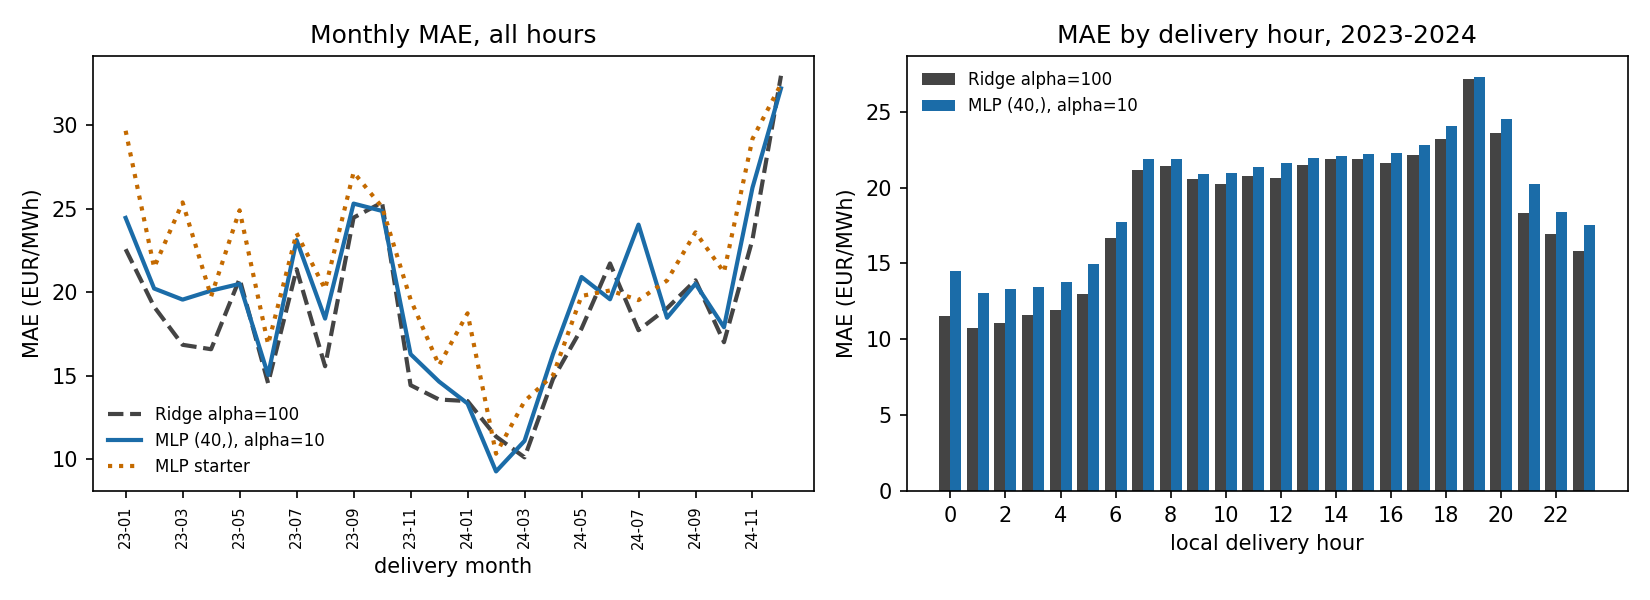

In [7]:
night = hours[hours.index.isin([0, 1, 2, 3, 4, 5, 21, 22, 23])]
day = hours[hours.index.isin(range(7, 20))]
print(f'mean MAE over night hours : ridge {night.ridge.mean():.2f}, mlp {night.mlp.mean():.2f} '
      f'(+{night.mlp.mean() - night.ridge.mean():.2f})')
print(f'mean MAE over 07-19       : ridge {day.ridge.mean():.2f}, mlp {day.mlp.mean():.2f} '
      f'(+{day.mlp.mean() - day.ridge.mean():.2f})')
print('hours where the network is better than Ridge:',
      [int(h) for h in hours.index[hours.mlp < hours.ridge]])
display(Image(filename=str(WORKSPACE / 'summary' / 'mlp_diagnostics.png')))

The tuned network improves on the starter in both years. Against Ridge it wins 2 of 12 months in
2023 and 6 of 12 in 2024. It loses 6.3 EUR/MWh in July 2024 and wins 2.1 in February 2024.

Ridge has the lower observed annual MAE in both years. The tuned MLP's gap is **+1.44 EUR/MWh in
2023**, the year used to select settings. In **2024 the observed gap is +0.85 EUR/MWh**. All three
dependence-aware 95% intervals include zero in 2024. The 7-day block interval is
[−0.04, +1.75] EUR/MWh, so the evidence for a systematic difference in that year is inconclusive.

The error is **concentrated at night**: the network is worse than Ridge at all 24 clock hours, by about
2.0 EUR/MWh over 00–05 and 21–23 (worst at 00:00, +3.0) but only 0.6 over 07–19. The 00–05 hours are the
low-price hours where Ridge is very accurate (MAE 10.7–13.5), and the shared all-hour MAE weights them
heavily, so the annual figure overstates how far behind the network is during the expensive evening hours.

### Part 7 · The chosen model and the hand-off

`model.py` keeps `build_model()`: one hidden layer of 40 units, `alpha=10`, `max_iter=800`, scaling of the
604 inputs and of the 24 targets inside the pipeline, fixed seed. It returns an unfitted estimator, so the
benchmark's monthly refit never sees evaluation days.

In [8]:
from model import build_model

chosen = build_model()
network = chosen.regressor.named_steps['mlpregressor']
print('hidden_layer_sizes', network.hidden_layer_sizes, '| alpha', network.alpha,
      '| max_iter', network.max_iter, '| early_stopping', network.early_stopping)

rng = np.random.default_rng(42)                     # same interface check as tests/test_team_workflow.py
smoke_x, smoke_y = rng.normal(size=(40, 5)), rng.normal(size=(40, 24))
smoke = build_model().fit(smoke_x, smoke_y).predict(smoke_x[:3])
print('smoke test shape', smoke.shape, '| finite', bool(np.isfinite(smoke).all()))

print()
print((WORKSPACE / 'model.py').read_text(encoding='utf-8'))

hidden_layer_sizes (40,) | alpha 10.0 | max_iter 800 | early_stopping False
smoke test shape (3, 24) | finite True

"""Multi-output neural network for the 24 local delivery hours.

The starting network was ``(80, 40)`` units with ``alpha=1.0`` and a
400-iteration budget. Rolling validation over the 2023 months
(``team/d-mlp/tuning.py``) selected one hidden layer of 40 units, ``alpha=10``
and an 800-iteration budget: the optimiser stops on its tolerance after about
268 epochs on average, so the larger budget never binds and produces the same
predictions as 400 in every refit.

Scaling of the 604 inputs and of the 24 targets is fitted inside the training
window only, so the benchmark's monthly refit never sees evaluation days.
"""

from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def build_model():
    """Build a fresh estimator that predicts

Hand-off to the project lead: `model.py`, the settings and the account in `README.md`, plus
`results/team/mlp/metrics.csv`, `results/team/mlp/timing.csv`, `results/team/mlp/run.json` and the
aligned `results/team/mlp/predictions.csv.gz` (Git-ignored; send through the agreed private channel).
`summary/` holds the tables used above so they can be checked without rerunning the fits.